In [7]:
import pandas as pd
from sklearn.linear_model import LinearRegression, Lasso

print("Ready for car price prediction")


Ready for car price prediction


In [8]:
url = "https://raw.githubusercontent.com/RimjimRazdan/cars_price_prediction/master/car%20data.csv"
cars = pd.read_csv(url)

print("Rows:", len(cars))
print("Columns:", len(cars.columns))
cars.head()

Rows: 301
Columns: 9


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [9]:
print("Missing values in each column:")
print(cars.isna().sum())

print("\nNumber of duplicate rows:", cars.duplicated().sum())

print("\nLabels used in each category:")
for column in ["Fuel_Type", "Seller_Type", "Transmission"]:
    print(column, "→", cars[column].dropna().unique().tolist())

Missing values in each column:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Number of duplicate rows: 2

Labels used in each category:
Fuel_Type → ['Petrol', 'Diesel', 'CNG']
Seller_Type → ['Dealer', 'Individual']
Transmission → ['Manual', 'Automatic']


In [10]:
cars_clean = cars.drop_duplicates().reset_index(drop=True)

print("Rows removed:", len(cars) - len(cars_clean))
print("Duplicates remaining:", cars_clean.duplicated().sum())

Rows removed: 2
Duplicates remaining: 0


In [6]:
from sklearn.model_selection import train_test_split

# X contains the car details. y contains the price we want to predict.
X = cars_clean.drop(columns=["Selling_Price"])
y = cars_clean["Selling_Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 239
Testing rows: 60


In [11]:
numeric_features = X_train.select_dtypes(include="number")
price_correlations = numeric_features.corrwith(y_train)

print(price_correlations.sort_values(ascending=False).round(2))


Present_Price    0.90
Year             0.21
Kms_Driven       0.14
Owner           -0.11
dtype: float64


In [12]:
# Write a one-line observation using your Step 6 results
feature = price_correlations.abs().idxmax()
print(f"{feature} has the strongest linear relationship with selling price "
      f"among the numeric inputs (r = {price_correlations[feature]:.2f}).")

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_columns = ["Year", "Present_Price", "Kms_Driven", "Owner"]
category_columns = ["Fuel_Type", "Seller_Type", "Transmission"]

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_columns),
    ("category", OneHotEncoder(handle_unknown="ignore"), category_columns)
])

X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)

print("Training shape:", X_train_ready.shape)
print("Testing shape:", X_test_ready.shape)

Present_Price has the strongest linear relationship with selling price among the numeric inputs (r = 0.90).
Training shape: (239, 11)
Testing shape: (60, 11)


In [13]:
linear_model = LinearRegression()
linear_model.fit(X_train_ready, y_train)

lasso_model = Lasso(alpha=0.1, max_iter=10000)
lasso_model.fit(X_train_ready, y_train)

linear_predictions = linear_model.predict(X_test_ready)
lasso_predictions = lasso_model.predict(X_test_ready)

comparison = pd.DataFrame({
    "Actual price": y_test,
    "Linear prediction": linear_predictions,
    "Lasso prediction": lasso_predictions
})

display(comparison.head().round(2))

,Actual price,Linear prediction,Lasso prediction
281,8.99,7.50,7.55
265,8.35,7.79,7.10
164,0.45,1.37,1.62
9,7.45,7.01,6.47
77,5.25,11.16,10.93


In [14]:
from sklearn.metrics import r2_score, mean_absolute_error

scores = pd.DataFrame({
    "Model": ["Linear Regression", "Lasso"],
    "R²": [
        r2_score(y_test, linear_predictions),
        r2_score(y_test, lasso_predictions)
    ],
    "MAE (₹ lakh)": [
        mean_absolute_error(y_test, linear_predictions),
        mean_absolute_error(y_test, lasso_predictions)
    ]
})

display(scores.round(3))

,Model,R²,MAE (₹ lakh)
0,Linear Regression,0.753,1.473
1,Lasso,0.754,1.488


On the 60 test cars, Linear Regression was off by ₹147,289 on average.
On the 60 test cars, Lasso was off by ₹148,802 on average.


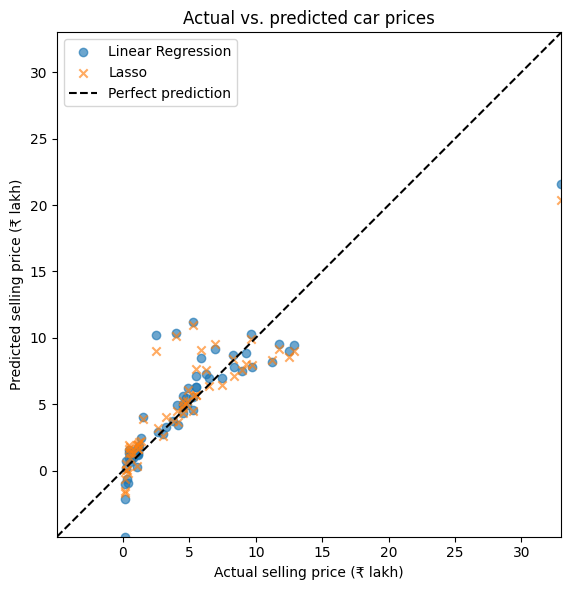

In [15]:
import matplotlib.pyplot as plt

# Summarize the average price error for each model
for model, mae in zip(scores["Model"], scores["MAE (₹ lakh)"]):
    print(f"On the 60 test cars, {model} was off by ₹{mae * 100000:,.0f} on average.")

# Use the same scale on both axes so the diagonal means a perfect prediction
low = min(y_test.min(), linear_predictions.min(), lasso_predictions.min())
high = max(y_test.max(), linear_predictions.max(), lasso_predictions.max())

plt.figure(figsize=(7, 6))
plt.scatter(y_test, linear_predictions, alpha=0.65, label="Linear Regression")
plt.scatter(y_test, lasso_predictions, alpha=0.65, marker="x", label="Lasso")
plt.plot([low, high], [low, high], "k--", label="Perfect prediction")
plt.xlim(low, high)
plt.ylim(low, high)
plt.gca().set_aspect("equal")
plt.xlabel("Actual selling price (₹ lakh)")
plt.ylabel("Predicted selling price (₹ lakh)")
plt.title("Actual vs. predicted car prices")
plt.legend()
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=200)
plt.show()

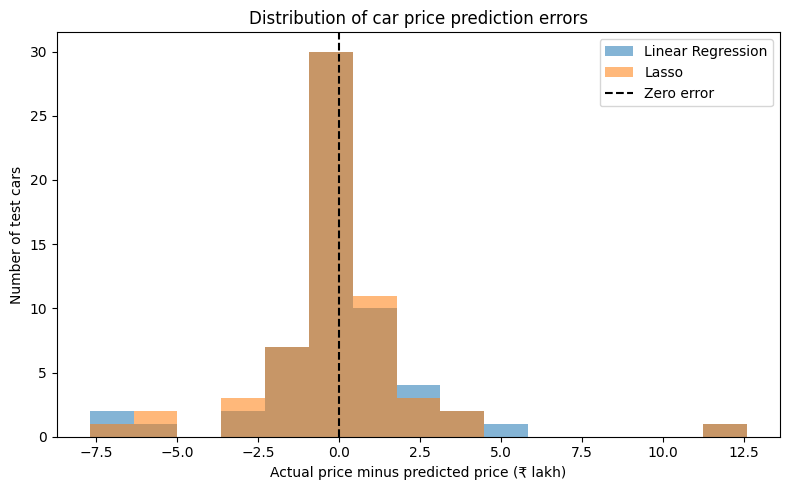

In [16]:
import numpy as np

# Prediction error (residual) = actual price minus predicted price
linear_errors = y_test - linear_predictions
lasso_errors = y_test - lasso_predictions

# Use the same price intervals to compare both models
bins = np.histogram_bin_edges(np.concatenate([linear_errors, lasso_errors]), bins=15)

plt.figure(figsize=(8, 5))
plt.hist(linear_errors, bins=bins, alpha=0.55, label="Linear Regression")
plt.hist(lasso_errors, bins=bins, alpha=0.55, label="Lasso")
plt.axvline(0, color="black", linestyle="--", label="Zero error")
plt.xlabel("Actual price minus predicted price (₹ lakh)")
plt.ylabel("Number of test cars")
plt.title("Distribution of car price prediction errors")
plt.legend()
plt.tight_layout()
plt.savefig("prediction_errors.png", dpi=200)
plt.show()

In [17]:
def predict_car_price(year, present_price_lakh, kms_driven, owner,
                      fuel_type, seller_type, transmission):
    car = pd.DataFrame([{
        "Year": year,
        "Present_Price": present_price_lakh,
        "Kms_Driven": kms_driven,
        "Owner": owner,
        "Fuel_Type": fuel_type,
        "Seller_Type": seller_type,
        "Transmission": transmission
    }])

    car_ready = preprocessor.transform(car)
    linear_price = linear_model.predict(car_ready)[0]
    lasso_price = lasso_model.predict(car_ready)[0]

    print(f"Linear Regression estimate: ₹{linear_price:.2f} lakh")
    print(f"Lasso estimate: ₹{lasso_price:.2f} lakh")


predict_car_price(
    year=2015,
    present_price_lakh=6.5,
    kms_driven=40000,
    owner=0,
    fuel_type="Petrol",
    seller_type="Dealer",
    transmission="Manual"
)

Linear Regression estimate: ₹4.53 lakh
Lasso estimate: ₹4.70 lakh
